# Earth-to-Mars Planner

In [1]:
%load_ext autoreload
%autoreload 2

In [63]:
import numpy as np
from numpy.linalg import norm
from tqdm import tqdm
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import juliandate as jd
from dataclasses import dataclass

from cesium.math.rotations import wrap_to_2pi, wrap_to_pi, dcm_x, dcm_z
from cesium.math.time import greg_to_jd, jd_to_greg
from cesium.orbital.ephemeris import planet_elements_and_rv
from cesium.orbital.transformations import ECI_from_HCI
from cesium.physics.dynamics import two_body
from cesium.orbital.porkchop import plot_porkchop
from cesium.orbital.interplanetary import departure_characteristics, calc_transfer
from cesium.world.constants import MU_SUN, R_SUN
from cesium.constants import C_LIGHT, DAY_TO_SEC, RAD_TO_DEG, M_TO_KM, AU_TO_M
from cesium.plotting import plot_3d
from lamberthub import izzo2015


## Time grid for intercept
From wikipedia, around 2035-2036 is optimal:

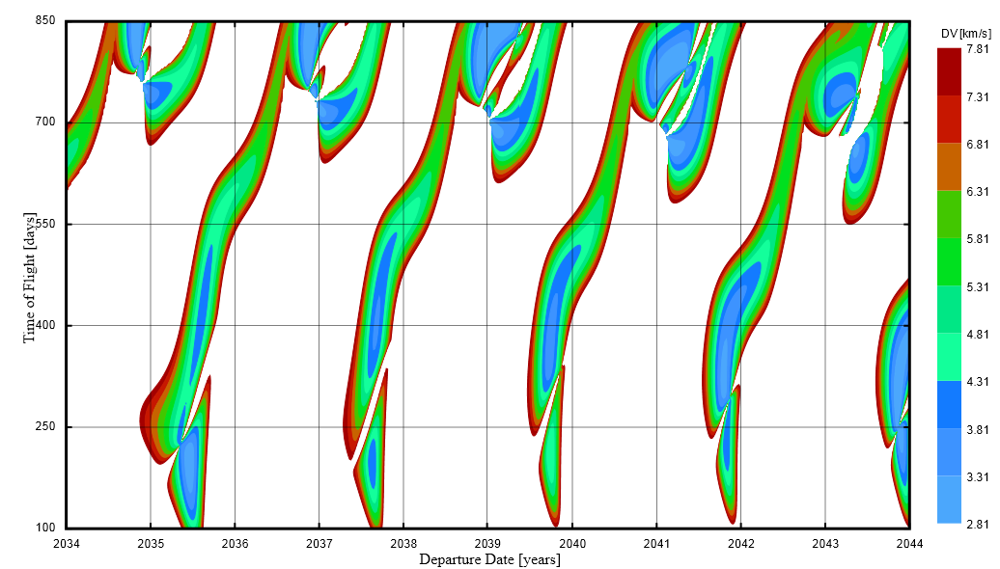

In [3]:
# start_jd = greg_to_jd(2043,6,0,0,0,0)
# end_jd = greg_to_jd(2044,6,0,0,0,0)
start_jd = greg_to_jd(2034,6,1,0,0,0)
end_jd = greg_to_jd(2036,1,1,0,0,0)
tof_bounds = (100,550)

t_dep_jd = np.arange(start_jd, end_jd)
t_arr_jd = np.arange(start_jd + tof_bounds[0], end_jd + tof_bounds[1])
N_DEP = len(t_dep_jd)
N_ARR = len(t_arr_jd)
print(f"Search space length: ({N_DEP},{N_ARR})")


t_tot_jd = np.sort(np.concatenate((t_dep_jd, t_arr_jd)))

dep_grid_jd, arr_grid_jd = np.meshgrid(
    t_dep_jd,
    t_arr_jd,
    indexing="ij"
)
tof_grid_jd = arr_grid_jd - dep_grid_jd

Search space length: (579,1029)


## Calculate characteristics

In [4]:
rv_dep_earth_hci = np.array([np.ravel(planet_elements_and_rv(3, t)[1:]) for t in t_dep_jd])
rv_arr_mars_hci = np.array([np.ravel(planet_elements_and_rv(4, t)[1:]) for t in t_arr_jd])

dcm_eci_wrt_hci = ECI_from_HCI()

In [ ]:
class InterplanetaryTransferGrid:
    """Everything in KM and KM/S. TODO: class methods for different initialization"""
    def __init__(self, name: str, departure_start_jd: float, departure_end_jd: float, tof_bounds: tuple, planet_nums: tuple[int, int], verbose = True):

        self.name = name
        self.verbose = verbose
        # Time
        self.departure_start_jd = departure_start_jd
        self.departure_end_jd = departure_end_jd
        self.tof_bounds = tof_bounds

        self.t_dep_jd = np.arange(start_jd, end_jd)
        self.t_arr_jd = np.arange(start_jd + tof_bounds[0], end_jd + tof_bounds[1])
        self.n_dep = len(t_dep_jd)
        self.n_arr = len(t_arr_jd)

        self.t_tot_jd = np.sort(np.concatenate((t_dep_jd, t_arr_jd)))

        dep_grid_jd, arr_grid_jd = np.meshgrid(
            t_dep_jd,
            t_arr_jd,
            indexing="ij"
        )
        self.tof_grid_jd = arr_grid_jd - dep_grid_jd


        # Planets (indexed on arrival and departure date lengths)
        self.rv_dep_body_hci = np.array([np.ravel(planet_elements_and_rv(3, t)[1:]) for t in t_dep_jd])
        self.rv_arr_body_hci = np.array([np.ravel(planet_elements_and_rv(4, t)[1:]) for t in t_arr_jd])

        if verbose:
            print(f"'{name}' - Initialized with:")
            print(f"\tSearch space of: ({self.n_dep}, {self.n_arr}) days")

    def compute_grid(self):

        # Solutions
        self.C3_grid_km2 = np.full((self.n_dep, self.n_arr), np.nan)

        self.v_dep_pci_km = np.full((self.n_dep, self.n_arr, 3), np.nan)  # subtracting body velocities
        self.v_arr_pci_km = np.full((self.n_dep, self.n_arr, 3), np.nan)  # subtracting body velocities

        self.v1_dep_hci_km = np.full((self.n_dep, self.n_arr, 3), np.nan)  # from lambert
        self.v2_arr_hci_km = np.full((self.n_dep, self.n_arr, 3), np.nan)  # from lambert

        # Calculation
        self.failed_transfers = []

        if self.verbose:
            print(f"`{self.name}` - Computing grid:")
        for dep_i in tqdm(range(self.n_dep)):
            rv_dep = self.rv_dep_body_hci[dep_i]

            for arr_i in range(N_ARR):
                rv_arr = self.rv_arr_body_hci[arr_i]
                tof = self.tof_grid_jd[dep_i, arr_i]

                if not tof_bounds[0] <= tof <= tof_bounds[1]:
                    continue
                try:
                    v1, v2 = calc_transfer(rv_dep[:3], rv_arr[:3], tof * DAY_TO_SEC)
                except ValueError as e:
                    self.failed_transfers.append((self.t_dep_jd[dep_i], self.t_arr_jd[arr_i], str(e)))
                    print(f"Failed transfer: departure JD {self.t_dep_jd[dep_i]}, arrival JD {self.t_arr_jd[arr_i]}: {e}")
                    continue

                v1_hci = v1 - rv_dep[3:6]
                v2_hci = v2 - rv_arr[3:6]

                C3 = norm(v1_hci) ** 2
                self.C3_grid_km2[dep_i, arr_i] = C3 * M_TO_KM*M_TO_KM
                self.v_dep_pci_km[dep_i, arr_i] = v1_hci * M_TO_KM
                self.v_arr_pci_km[dep_i, arr_i] = v2_hci * M_TO_KM
                
                self.v1_dep_hci_km[dep_i, arr_i] = v1 * M_TO_KM
                self.v2_arr_hci_km[dep_i, arr_i] = v2 * M_TO_KM

        if self.verbose and len(self.failed_transfers) > 1:
            print(f"{len(self.failed_transfers)} failed transfers; see failed_transfers for dates and errors.")

In [60]:
earth_to_mars = InterplanetaryTransferGrid("Earth to Mars Transfer", start_jd, end_jd, tof_bounds, (3,4))
earth_to_mars.compute_grid()


'Earth to Mars Transfer' initialized with:
	Search space of: (579, 1029) days
`Earth to Mars Transfer` - Computing grid:


100%|██████████| 579/579 [00:08<00:00, 72.12it/s]


In [ ]:
@dataclass
class EarthDepartureGrid:
    grid: InterplanetaryTransferGrid

    def __post_init__(self):
        dcm_eci_wrt_hci = ECI_from_HCI()
        v1_hci = v1 - rv_dep[3:6]  # Earth-relative, expressed in HCI axes
        v2_hci = v2 - rv_arr[3:6]  # Mars-relative, expressed in HCI axes
        v1_eci = dcm_eci_wrt_hci @ v1_hci
        C3, rla, dla = departure_characteristics(v1_eci)
        

A


EarthDepartureGrid(grid=<__main__.InterplanetaryTransferGrid object at 0x113691250>)

## Plots

In [7]:
common_options = {
    "xlabel": "Earth departure Date",
    "ylabel": "Time-of-flight [day]",
    "xaxis": "gregorian",      
    "yaxis": "time-of-flight", 
    "xrange": (start_jd, end_jd),
    "yrange": tof_bounds,
    "show": True,
}

In [61]:
fig = plot_porkchop(
    t_dep_jd, t_arr_jd, earth_to_mars.C3_grid_km2,
    # zmin=0, zmax=100,
    contour_min=2.81**2, contour_max=7.81**2, contour_step=2,  # same bounds as nasa plot
    title="Earth-to-Mars departure C3",
    zlabel="C3 [km²/s²]",
    **common_options,
)

In [ ]:
fig = plot_porkchop(
    t_dep_jd, t_arr_jd, earth_to_mars.dla_grid,
    contour_min=-40, contour_max=40, contour_step=2,
    title="Earth-to-Mars Declination",
    zlabel="Declination [º]",
    hovertemplate="Departure offset: %{x} days<br>Arrival offset: %{y} days<br>DLA: %{z:.2f}º<extra></extra>",
    **common_options,
)

AttributeError: 'InterplanetaryTransferGrid' object has no attribute 'dla_grid'

In [10]:
v_dep_hci_km_norm = norm(earth_to_mars.v_dep_pci_km, axis=2)
v_arr_hci_km_norm = norm(earth_to_mars.v_arr_pci_km, axis=2)

fig = plot_porkchop(
    t_dep_jd, t_arr_jd, v_arr_hci_km_norm,
    # zmin=0, zmax=100,
    contour_min=0, contour_max=10, contour_step=1,
    title="Earth-to-Mars Arrival Excess Speed",
    zlabel="V_arr_inf in HCI [km/s]",
    **common_options,
)

## Constraints

In [11]:
ARRIVAL_JD = 2461633
C3_MAX_KM = 15.0  # km/s
DLA_MAX = 33.0  # deg
V_ARR_MAX_KM = 3.5 # km/s



C3_mask = earth_to_mars.C3_grid_km2.copy()
C3_mask[earth_to_mars.C3_grid_km2 > C3_MAX_KM] = np.nan
C3_mask[abs(earth_to_mars.dla_grid) >= DLA_MAX] = np.nan
# C3_mask[v_arr_inf_norm >= V_ARR_MAX] = np.nan


In [12]:
fig = plot_porkchop(
    t_dep_jd, t_arr_jd, C3_mask,
    zmin=0, zmax=C3_MAX_KM,
    contour_min=0, contour_max=C3_MAX_KM, contour_step=0.5,
    title="Earth-to-Mars departure C3 with constraints",
    zlabel="C3 [km²/s²]",
    **common_options,
)


## Selecting trajectory

In [13]:
BIRTHDAY_JD = (6,13)
birthday_mask = np.array([jd_to_greg(t)[1:3] == BIRTHDAY_JD for t in t_dep_jd])

C3_birthday = np.where(birthday_mask[:, None], C3_mask, np.nan)  # keeps C3_mask, discards np.nan
birthday_dep_i, birthday_arr_i = np.where(np.isfinite(C3_birthday))
birthday_departure_jd, birthday_arrival_jd = t_dep_jd[birthday_dep_i], t_arr_jd[birthday_arr_i]
birthday_c3 = C3_birthday[birthday_dep_i, birthday_arr_i]

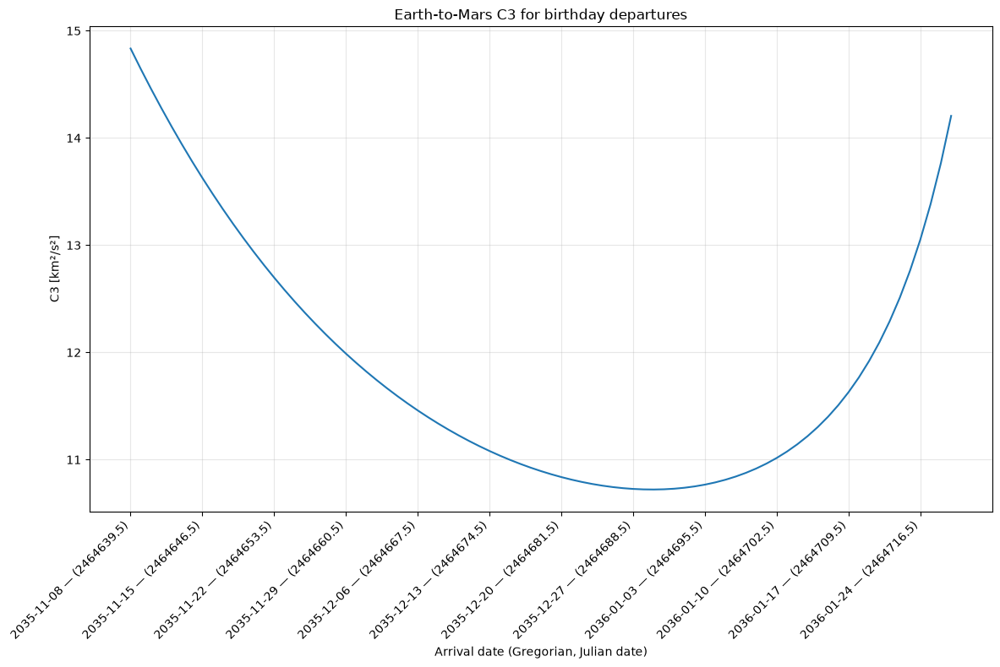

In [14]:
plt.figure(figsize=(12,8))
plt.plot(birthday_arrival_jd, birthday_c3)
plt.ylabel("C3 [km²/s²]")
plt.xlabel("Arrival date (Gregorian, Julian date)")
plt.gca().xaxis.set_major_formatter(lambda jd, _: "{:04.0f}-{:02.0f}-{:02.0f} — ({:.1f})".format(*jd_to_greg(jd)[:3], jd))

plt.gca().set_xticks(np.arange(birthday_arrival_jd.min(), birthday_arrival_jd.max() + 1, 7))
plt.xticks(rotation=45, ha="right")

plt.title("Earth-to-Mars C3 for birthday departures")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Modeling of my chosen trajectory
Decided to choose a trajectory on my birthday of June 13th, and on Christmas

In [15]:
ARRIVAL_JD = greg_to_jd(2035,12,25,0,0,0)

arrival_mask = t_arr_jd == ARRIVAL_JD

C3_selected = np.where(birthday_mask[:, None] & arrival_mask[None, :], C3_mask, np.nan)
birthday_dep_i, birthday_arr_i = np.where(np.isfinite(C3_selected))
birthday_departure_jd, birthday_arrival_jd = t_dep_jd[birthday_dep_i][0], t_arr_jd[birthday_arr_i][0]
birthday_c3 = C3_selected[birthday_dep_i, birthday_arr_i][0]

print(f"C3 for leaving on June 13 and arriving on December 25:\n\t{birthday_c3:.2f} km2/s2")

C3 for leaving on June 13 and arriving on December 25:
	10.74 km2/s2


In [16]:
# Trajectory Conditions
rv_dep_hci = np.concatenate((rv_dep_earth_hci[birthday_dep_i][0][0:3], earth_to_mars.v1_hci_grid_km[birthday_dep_i, birthday_arr_i][0] / M_TO_KM))

# Earth
rv_earth_birthday_hci = rv_dep_earth_hci[birthday_dep_i[0]:,0:3]
t_birthday_dep_jd = t_dep_jd[birthday_dep_i[0]:]

# Mars (departure through arrival)
mars_mask = (t_arr_jd >= birthday_departure_jd) & (t_arr_jd <= birthday_arrival_jd)
rv_mars_birthday_hci = rv_arr_mars_hci[mars_mask, :3]
t_birthday_arr_jd = t_arr_jd[mars_mask]

In [17]:
t_coast_arr = np.linspace(birthday_departure_jd, birthday_arrival_jd, 10000) * DAY_TO_SEC
assert (t_coast_arr[1] - t_coast_arr[0]) < 0.1*DAY_TO_SEC  # Make sure less than 0.1 day spacing

sat_coast = solve_ivp(lambda _,s: two_body(s, MU_SUN), (t_coast_arr[0], t_coast_arr[-1]), rv_dep_hci, t_eval=t_coast_arr, rtol=1e-9,atol=1e-12)

r_sat_coast_hci = sat_coast.y.T[:,:3]

print(f"Position difference (m): {norm(r_sat_coast_hci[-1, 0:3] - rv_mars_birthday_hci[-1])}")

Position difference (m): 597.7962103981309


In [18]:
fig = plot_3d([r_sat_coast_hci, rv_earth_birthday_hci, rv_mars_birthday_hci], [t_coast_arr, t_birthday_dep_jd, t_birthday_arr_jd], 
              labels=["Satellite", "Earth", "Mars"], bodies={"name": "Sun", "radius": R_SUN*5, "color": "goldenrod"}, title="Birthday Mission", show=False,
              azim=80, elev=30, camera_distance=3, units="AU", scale=AU_TO_M)
fig.show()

## Save results!
- Launch date [jd]
- Arrival date [jd]
- Time of flight [s]
- dt [s]
- Time grid [s]
- Earth HCI rv [km, km/s]
- Mars HCI rv [km, km/s]
- Satellite HCI rv [km, km/s]

In [19]:
from pathlib import Path

assert sat_coast.success, sat_coast.message
mission_time_s = sat_coast.t - sat_coast.t[0]
mission_jd = sat_coast.t / DAY_TO_SEC
earth_rv_hci_km = np.array([np.concatenate(planet_elements_and_rv(3, jd)[1:]) for jd in mission_jd]) * M_TO_KM
mars_rv_hci_km = np.array([np.concatenate(planet_elements_and_rv(4, jd)[1:]) for jd in mission_jd]) * M_TO_KM

mission_path = Path("trajectories/birthday-christmas.mission")
mission_path.parent.mkdir(parents=True, exist_ok=True)
with mission_path.open("wb") as file:
    np.savez_compressed(
        file, launch_jd=birthday_departure_jd, arrival_jd=birthday_arrival_jd,
        tof_s=mission_time_s[-1], dt_s=mission_time_s[1] - mission_time_s[0],
        time_s=mission_time_s, earth_rv_hci_km=earth_rv_hci_km,
        mars_rv_hci_km=mars_rv_hci_km, satellite_rv_hci_km=sat_coast.y.T * M_TO_KM,
        frame="HCI", position_units="km", velocity_units="km/s", time_origin="launch",
    )
print(mission_path)

trajectories/birthday-christmas.mission


## Thoughts

Next step would be modeling a range of dates to see what the best would be